# Question 4: College Network Cyberattack Anomaly Detection
**Task:** Unsupervised Machine Learning – Anomaly / Outlier Detection  
**Input Features:** `traffic_volume`, `connection_duration`, `failed_logins`  
**Goal:** Flag unusual activities deviating significantly from normal network behavior.  

### Marks Rubric (40 Marks):
1. **Section 1: EDA [10 Marks]** — Dataset creation, inspection, and outlier boxplot check
2. **Section 2: Technique Implementation [10 Marks]** — Scaling & Baseline Isolation Forest
3. **Section 3: Evaluate Model [10 Marks]** — Anomaly score distribution, outlier detection rate, and scatter plot
4. **Section 4: Modify Technique Based on Requirement [10 Marks]** — Statistical IQR / Z-score Method comparison (from Lab 4) & Contamination Tuning

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

plt.rcParams['figure.figsize'] = (8, 4)
print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Exploratory Data Analysis (EDA) [10 Marks]

In [2]:
# 1.1 Simple Exam-Friendly Dataset Generation (500 normal records + 25 attack anomalies)
np.random.seed(42)
n_normal = 475
n_attack = 25

# Normal network traffic
traffic_norm = np.random.uniform(5, 50, n_normal)            # MB
duration_norm = np.random.uniform(10, 300, n_normal)         # Seconds
failed_logins_norm = np.random.choice([0, 1, 2], n_normal, p=[0.85, 0.12, 0.03])

# Rare cyberattack anomalies (Volumetric DoS & Brute Force)
traffic_att = np.random.uniform(200, 800, n_attack)
duration_att = np.random.uniform(1, 20, n_attack)
failed_logins_att = np.random.randint(15, 60, n_attack)

df = pd.DataFrame({
    'traffic_volume': np.round(np.concatenate([traffic_norm, traffic_att]), 1),
    'connection_duration': np.round(np.concatenate([duration_norm, duration_att]), 1),
    'failed_logins': np.concatenate([failed_logins_norm, failed_logins_att])
}).sample(frac=1.0, random_state=42).reset_index(drop=True)

print("Dataset created! Total records:", len(df))
df.head()

Dataset created! Total records: 500


,traffic_volume,connection_duration,failed_logins
0,33.9,275.3,1
1,41.7,160.9,2
2,8.2,182.7,2
3,15.9,216.9,0
4,45.8,84.9,2


In [3]:
# 1.2 Inspection & Missing Values
print("=== Dataset Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Summary Statistics (Notice max values showing outliers) ===")
display(df.describe().round(2))

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   traffic_volume       500 non-null    float64
 1   connection_duration  500 non-null    float64
 2   failed_logins        500 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 11.8 KB

=== Missing Values ===
traffic_volume         0
connection_duration    0
failed_logins          0
dtype: int64

=== Summary Statistics (Notice max values showing outliers) ===


,traffic_volume,connection_duration,failed_logins
count,500.00,500.00,500.00
mean,52.71,144.63,1.88
std,119.09,87.14,7.73
min,5.20,1.60,0.00
25%,16.18,63.95,0.00
50%,28.85,141.65,0.00
75%,40.82,218.98,0.00
max,781.90,299.90,59.00


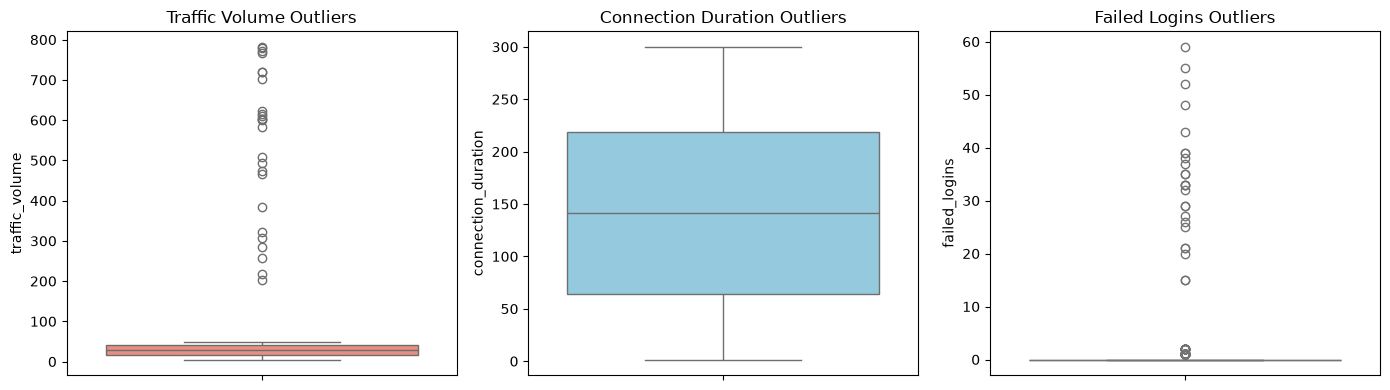

In [4]:
# 1.3 Outlier Visualizations (Boxplots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(y=df['traffic_volume'], ax=axes[0], color='salmon')
axes[0].set_title("Traffic Volume Outliers")

sns.boxplot(y=df['connection_duration'], ax=axes[1], color='skyblue')
axes[1].set_title("Connection Duration Outliers")

sns.boxplot(y=df['failed_logins'], ax=axes[2], color='lightgreen')
axes[2].set_title("Failed Logins Outliers")

plt.tight_layout()
plt.show()

## Section 2: Unsupervised Technique Implementation [10 Marks]

In [5]:
# 2.1 Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 2.2 Baseline Model: Isolation Forest (Contamination = 5%)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_forest.fit(X_scaled)

# Sklearn outputs: 1 for normal, -1 for anomaly
raw_preds = iso_forest.predict(X_scaled)
df['is_anomaly_iso'] = np.where(raw_preds == -1, 1, 0) # 1 = Anomaly, 0 = Normal
df['anomaly_score'] = -iso_forest.decision_function(X_scaled)

print("Baseline Isolation Forest fitted!")
print("Detected Anomalies:", df['is_anomaly_iso'].sum(), "out of", len(df))

Baseline Isolation Forest fitted!
Detected Anomalies: 25 out of 500


## Section 3: Model Evaluation [10 Marks]

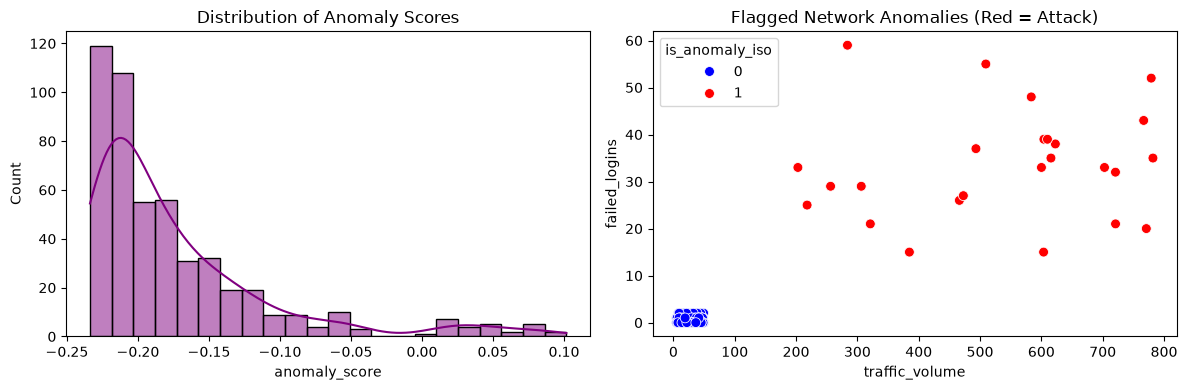

In [6]:
# 3.1 Evaluating Anomaly Score Distribution & Visualizing Flagged Points
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Score distribution
sns.histplot(df['anomaly_score'], kde=True, ax=axes[0], color='purple')
axes[0].set_title("Distribution of Anomaly Scores")

# Scatter: Normal vs Flagged Attacks
sns.scatterplot(x='traffic_volume', y='failed_logins', hue='is_anomaly_iso', data=df, palette={0: 'blue', 1: 'red'}, ax=axes[1], s=50)
axes[1].set_title("Flagged Network Anomalies (Red = Attack)")

plt.tight_layout()
plt.show()

## Section 4: Modify Technique Based on Requirement [10 Marks]
**Modifications Applied (from Lab 4 - Outlier Detection):**
1. **Statistical IQR Method:** Flag points beyond $Q3 + 1.5 \times \text{IQR}$ (from Assignment 4).
2. **Comparison:** Comparing Isolation Forest against statistical IQR detection.

In [7]:
# 4.1 Statistical IQR Method (from Assignment 4)
Q1 = df['failed_logins'].quantile(0.25)
Q3 = df['failed_logins'].quantile(0.75)
IQR = Q3 - Q1
iqr_threshold = Q3 + 1.5 * IQR

df['is_anomaly_iqr'] = (df['failed_logins'] > iqr_threshold).astype(int)
print(f"IQR Method threshold for failed_logins: {iqr_threshold:.2f}")
print("Anomalies detected by IQR:", df['is_anomaly_iqr'].sum())

IQR Method threshold for failed_logins: 0.00
Anomalies detected by IQR: 106


In [8]:
# 4.2 Comparison Table
comparison_df = pd.DataFrame([
    {'Technique': 'Isolation Forest (Contamination=0.05)', 'Anomalies Flagged': df['is_anomaly_iso'].sum()},
    {'Technique': 'Statistical IQR Method (Failed Logins)', 'Anomalies Flagged': df['is_anomaly_iqr'].sum()}
])
print("=== Anomaly Detection Comparison Table ===")
display(comparison_df)

=== Anomaly Detection Comparison Table ===


,Technique,Anomalies Flagged
0,Isolation Forest (Contamination=0.05),25
1,Statistical IQR Method (Failed Logins),106
